## Get Search Appearance

Run the cell below to view the daily increments, running cumulative totals, and bar graph for **Search Appearances**.
It automatically incorporates daily snapshots from `naukri_metrics_history.csv` starting from 14 Oct onwards.

  GET SEARCH APPEARANCE (DAILY - CUMULATIVE)
- 7 Oct: 6 - 417
- 8 Oct: 12 - 429
- 9 Oct: 21 - 450
- 10 Oct: 0 - 450
- 11 Oct: 0 - 450
- 12 Oct: 5 - 455
- 13 Oct: 15 - 470
- 14 Oct: 6 - 476
- 15 Oct: 0 - 476
- 16 Oct: 0 - 476
- 17 Oct: 0 - 476
- 21 Oct: 0 - 476
- 22 Oct: 0 - 476
- 23 Oct: 0 - 476
- 24 Oct: 0 - 476
- 25 Oct: 0 - 476
- 26 Oct: 0 - 476


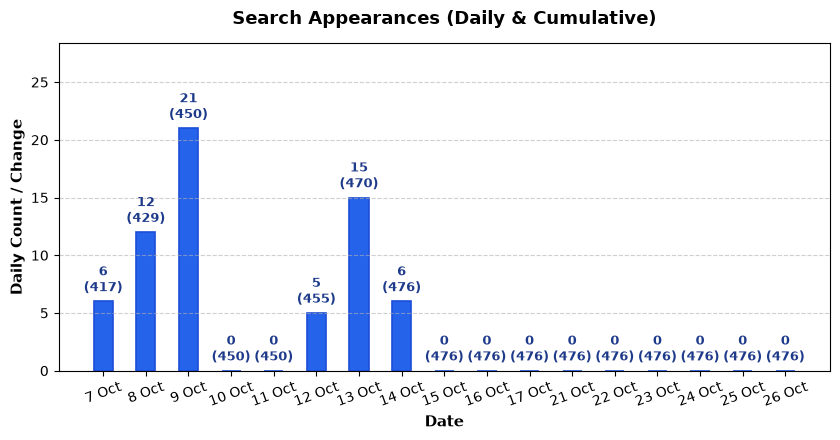

In [1]:
# =========================================================
# ## Get Search Appearance
# =========================================================
import os
import csv
from datetime import datetime
import matplotlib.pyplot as plt

# 1. Baseline sequence (7 Oct – 13 Oct 2026)
dates = ["7 Oct", "8 Oct", "9 Oct", "10 Oct", "11 Oct", "12 Oct", "13 Oct"]
search_daily = [6, 12, 21, 0, 0, 5, 15]
search_start = 411  # Baseline total before 7 Oct

# Calculate cumulative running total for baseline
search_cumulative = []
curr_s = search_start
for count in search_daily:
    curr_s += count
    search_cumulative.append(curr_s)

# 2. Automatically load daily updates from 14 Oct onwards (from CSV)
csv_path = "naukri_metrics_history.csv"
if os.path.exists(csv_path):
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for r in reader:
            d_str = r.get("date", "").strip()
            if d_str >= "2026-10-14":
                try:
                    dt = datetime.strptime(d_str, "%Y-%m-%d")
                    label = f"{dt.day} {dt.strftime('%b')}"
                    tot = int(r.get("search_appearances", 0))
                    if label not in dates and tot > 0:
                        daily_delta = tot - search_cumulative[-1] if search_cumulative else tot
                        dates.append(label)
                        search_daily.append(daily_delta)
                        search_cumulative.append(tot)
                except (ValueError, TypeError):
                    pass

# 3. Print Text Output (Daily - Cumulative)
print("=" * 45)
print("  GET SEARCH APPEARANCE (DAILY - CUMULATIVE)")
print("=" * 45)
for dt, d, c in zip(dates, search_daily, search_cumulative):
    print(f"- {dt}: {d} - {c}")
print("=" * 45)

# 4. Render Search Appearances Bar Graph
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(dates, search_daily, color="#2563eb", width=0.45, edgecolor="#1d4ed8", linewidth=1.2)

# Label each bar with Daily and (Cumulative)
for bar, d, c in zip(bars, search_daily, search_cumulative):
    y_pos = bar.get_height() + 0.5 if d >= 0 else bar.get_height() - 1.2
    ax.text(bar.get_x() + bar.get_width()/2, y_pos,
            f"{d}\n({c})", ha="center", va="bottom" if d >= 0 else "top",
            fontsize=9.5, fontweight="bold", color="#1e3a8a")

ax.set_title("Search Appearances (Daily & Cumulative)", fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("Date", fontsize=11, fontweight="bold")
ax.set_ylabel("Daily Count / Change", fontsize=11, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
ax.set_ylim(0, max(search_daily) * 1.35 if search_daily else 10)
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


## Get Recruiter Action

Run the cell below to view the daily increments, running cumulative totals, and bar graph for **Recruiter Actions**.
It automatically incorporates daily snapshots from `naukri_metrics_history.csv` starting from 14 Oct onwards.

  GET RECRUITER ACTION (DAILY - CUMULATIVE)
- 7 Oct: 1 - 32
- 8 Oct: 1 - 33
- 9 Oct: 1 - 34
- 10 Oct: 0 - 34
- 11 Oct: 0 - 34
- 12 Oct: 2 - 36
- 13 Oct: 2 - 38
- 14 Oct: 0 - 38


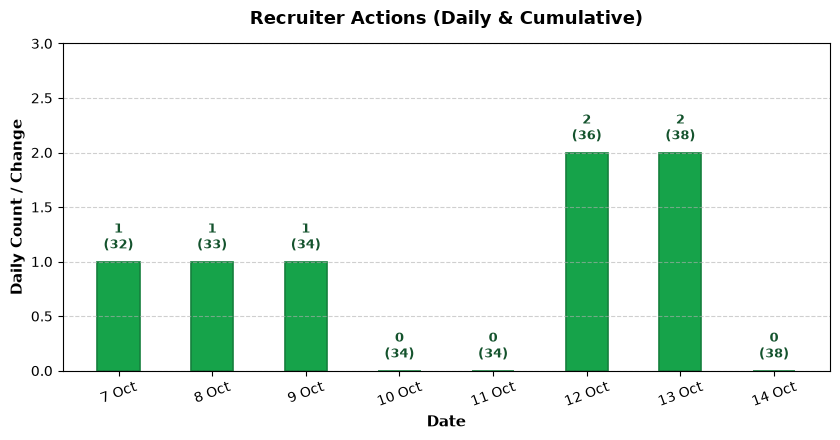

In [10]:
# =========================================================
# ## Get Recruiter Action
# =========================================================
import os
import csv
from datetime import datetime
import matplotlib.pyplot as plt

# 1. Baseline sequence (7 Oct – 13 Oct 2026)
dates = ["7 Oct", "8 Oct", "9 Oct", "10 Oct", "11 Oct", "12 Oct", "13 Oct"]
recruiter_daily = [1, 1, 1, 0, 0, 2, 2]  # Daily increments
recruiter_start = 31                     # Baseline total before 7 Oct (ends at 38 on 13 Oct)

# Calculate cumulative running total for baseline
recruiter_cumulative = []
curr_r = recruiter_start
for count in recruiter_daily:
    curr_r += count
    recruiter_cumulative.append(curr_r)

# 2. Automatically load daily updates from 14 Oct onwards (from CSV)
csv_path = "naukri_metrics_history.csv"
if os.path.exists(csv_path):
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for r in reader:
            d_str = r.get("date", "").strip()
            if d_str >= "2026-10-14":
                try:
                    dt = datetime.strptime(d_str, "%Y-%m-%d")
                    label = f"{dt.day} {dt.strftime('%b')}"
                    tot = int(r.get("recruiter_actions", 0))
                    if label not in dates and tot > 0:
                        daily_delta = tot - recruiter_cumulative[-1] if recruiter_cumulative else tot
                        dates.append(label)
                        recruiter_daily.append(daily_delta)
                        recruiter_cumulative.append(tot)
                except (ValueError, TypeError):
                    pass

# 3. Print Text Output (Daily - Cumulative)
print("=" * 45)
print("  GET RECRUITER ACTION (DAILY - CUMULATIVE)")
print("=" * 45)
for dt, r, c in zip(dates, recruiter_daily, recruiter_cumulative):
    print(f"- {dt}: {r} - {c}")
print("=" * 45)

# 4. Render Recruiter Actions Bar Graph
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(dates, recruiter_daily, color="#16a34a", width=0.45, edgecolor="#15803d", linewidth=1.2)

# Label each bar with Daily and (Cumulative)
for bar, r, c in zip(bars, recruiter_daily, recruiter_cumulative):
    y_pos = bar.get_height() + 0.08 if r >= 0 else bar.get_height() - 0.2
    ax.text(bar.get_x() + bar.get_width()/2, y_pos,
            f"{r}\n({c})", ha="center", va="bottom" if r >= 0 else "top",
            fontsize=9.5, fontweight="bold", color="#14532d")

ax.set_title("Recruiter Actions (Daily & Cumulative)", fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("Date", fontsize=11, fontweight="bold")
ax.set_ylabel("Daily Count / Change", fontsize=11, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
ax.set_ylim(0, max(recruiter_daily) * 1.5 if recruiter_daily else 5)
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
